# Analysis of Podcast Reviews dataset

## Introduction

A podcast is a digital program consisting of a series of episodes that you can download or stream from the internet. They are primarily an audio medium, with some of podcasts also offering a video component as well. 

In 2022 it was estimated that 62% of Americans will have listened to a podcast in their lifetime. This percentage has increased from 57% in 2021 (source: https://riverside.fm/blog/podcast-statistics). It is obvious that podcasts are becoming more and more popular. Therefore, it makes sence to analyse data from them to see if there are any tendencies.

**Dataset information**

2 million podcast reviews for 100k podcasts, updated monthly. This dataset is intended to aid in analysis of text feedback and review data. The dataset was taken from https://www.kaggle.com/datasets/thoughtvector/podcastreviews/versions/28.

**Project**

Podcast Reviews dataset is used for Inferential Statistical Analysis project of Data Analysis module sprint 2. Data analysis is done using python and pandas library. For visualization matplotlib, plotly and seaborn libraries were used.

The project is done using python (version 3.11.4), seaborn (0.12.2), numpy (1.26.1) (used in scripts.py file), matplotlib (3.8.0), pandas (2.0.3), duckdb (0.9.1) and scipy (1.11.2) libraries.

**Plan**

Explore date presented in the tables. Test three hypotheses.

**Dashboard**

This is a link to my created dashboard for this project:
https://lookerstudio.google.com/reporting/48ed55c4-1398-4f91-80fe-a86d25e3e891

# Preparation

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib as plt
import sqlite3
import duckdb as db
from os.path import exists
from scipy import stats
from scripts import *

### Loading the data

In [2]:
address = "data/database.sqlite"
con = sqlite3.connect(address)

query = """
SELECT * 
FROM sqlite_master 
WHERE type = 'table'
"""

table = pd.read_sql(query, con)
table

,type,name,tbl_name,rootpage,sql
0,table,runs,runs,2,CREATE TABLE runs (\n run_at text not n...
1,table,podcasts,podcasts,3,CREATE TABLE podcasts (\n podcast_id te...
2,table,categories,categories,5,CREATE TABLE categories (\n podcast_id ...
3,table,reviews,reviews,7,CREATE TABLE reviews (\n podcast_id tex...


There are 4 tables in our dataset: runs, podcasts, categories and reviews.

In [3]:
query = """
SELECT * 
FROM runs
"""

runs = pd.read_sql(query, con)
runs.head()

,run_at,max_rowid,reviews_added
0,2021-05-10 02:53:00,3266481,1215223
1,2021-06-06 21:34:36,3300773,13139
2,2021-07-02 18:04:55,3329699,11561
3,2021-08-01 17:54:42,3360315,11855
4,2021-09-02 18:00:30,3390165,11714


In [4]:
query = """
SELECT * 
FROM podcasts
"""

podcasts = pd.read_sql(query, con)
podcasts.head()

,podcast_id,itunes_id,slug,itunes_url,title
0,a00018b54eb342567c94dacfb2a3e504,1313466221,scaling-global,https://podcasts.apple.com/us/podcast/scaling-...,Scaling Global
1,a00043d34e734b09246d17dc5d56f63c,158973461,cornerstone-baptist-church-of-orlando,https://podcasts.apple.com/us/podcast/cornerst...,Cornerstone Baptist Church of Orlando
2,a0004b1ef445af9dc84dad1e7821b1e3,139076942,mystery-dancing-in-the-dark,https://podcasts.apple.com/us/podcast/mystery-...,Mystery: Dancing in the Dark
3,a00071f9aaae9ac725c3a586701abf4d,1332508972,kts-money-matters,https://podcasts.apple.com/us/podcast/kts-mone...,KTs Money Matters
4,a000a500f06555f81220c3eb641aded7,1544900779,word-on-the-street-w-dreak-swift,https://podcasts.apple.com/us/podcast/word-on-...,Word on the Street w/ Dreak Swift


In [5]:
query = """
SELECT * 
FROM categories
"""

categories = pd.read_sql(query, con)
categories.head()

,podcast_id,category
0,c61aa81c9b929a66f0c1db6cbe5d8548,arts
1,c61aa81c9b929a66f0c1db6cbe5d8548,arts-performing-arts
2,c61aa81c9b929a66f0c1db6cbe5d8548,music
3,ad4f2bf69c72b8db75978423c25f379e,arts
4,ad4f2bf69c72b8db75978423c25f379e,arts-design


In [6]:
query = """
SELECT * 
FROM reviews
"""

reviews = pd.read_sql(query, con)
reviews.head()

,podcast_id,title,content,rating,author_id,created_at
0,c61aa81c9b929a66f0c1db6cbe5d8548,really interesting!,Thanks for providing these insights. Really e...,5,F7E5A318989779D,2018-04-24T12:05:16-07:00
1,c61aa81c9b929a66f0c1db6cbe5d8548,Must listen for anyone interested in the arts!!!,Super excited to see this podcast grow. So man...,5,F6BF5472689BD12,2018-05-09T18:14:32-07:00
2,ad4f2bf69c72b8db75978423c25f379e,nauseatingly left,"I'm a liberal myself, but its pretty obvious a...",1,1AB95B8E6E1309E,2019-06-11T14:53:39-07:00
3,ad4f2bf69c72b8db75978423c25f379e,Diverse stories,I find Tedx talks very inspirational but I oft...,5,11BB760AA5DEBD1,2018-05-31T13:08:09-07:00
4,ad4f2bf69c72b8db75978423c25f379e,👍👍👍👍,"I love this podcast, it is so good.",5,D86032C8E57D15A,2019-06-19T13:56:05-07:00


### Checking for nulls

In [7]:
tables_list = ["runs", "podcasts", "categories", "reviews"]

In [8]:
print("Checking for rows with null values across all tables:")

for item in tables_list:
    print(item)
    temp = []
    col = eval(f"{item}.columns")
    for i in range(len(col)):
        temp.append(col[i])
        if i == (len(col) - 1):
            temp.append("IS NULL")
        else:
            temp.append("IS NULL OR")

    query = f"""
    SELECT *
    FROM {item}
    WHERE {' '.join(temp)}
    """
    print(db.sql(query))

Checking for rows with null values across all tables:
runs
┌─────────┬───────────┬───────────────┐
│ run_at  │ max_rowid │ reviews_added │
│ varchar │   int64   │     int64     │
├─────────────────────────────────────┤
│               0 rows                │
└─────────────────────────────────────┘

podcasts
┌────────────┬───────────┬─────────┬────────────┬─────────┐
│ podcast_id │ itunes_id │  slug   │ itunes_url │  title  │
│  varchar   │   int64   │ varchar │  varchar   │ varchar │
├─────────────────────────────────────────────────────────┤
│                         0 rows                          │
└─────────────────────────────────────────────────────────┘

categories
┌────────────┬──────────┐
│ podcast_id │ category │
│  varchar   │ varchar  │
├───────────────────────┤
│        0 rows         │
└───────────────────────┘

reviews
┌────────────┬─────────┬─────────┬────────┬───────────┬────────────┐
│ podcast_id │  title  │ content │ rating │ author_id │ created_at │
│  varchar   │ v

There are no nulls in any of the tables.

### Checking for duplicate values

#### Runs table

In [9]:
runs.duplicated().any()

False

In [10]:
runs.columns.duplicated().any()

False

#### Podcasts table

In [11]:
podcasts.duplicated().any()

False

In [12]:
podcasts.columns.duplicated().any()

False

#### Categories table

In [13]:
categories.duplicated().any()

False

In [14]:
categories.columns.duplicated().any()

False

#### Reviews table

In [15]:
query = """
SELECT podcast_id, title, content, rating, author_id, created_at, COUNT()
FROM reviews
GROUP BY podcast_id, title, content, rating, author_id, created_at
HAVING COUNT() > 1
"""
len(db.sql(query).df())

582

There are 582 duplicate values in reviews table which are going to be removed.

In [16]:
query = """
SELECT DISTINCT * 
FROM reviews
"""
reviews = db.sql(query).df()

In [17]:
query = """
SELECT podcast_id, title, content, rating, author_id, created_at, COUNT()
FROM reviews
GROUP BY podcast_id, title, content, rating, author_id, created_at
HAVING COUNT() > 1
"""
len(db.sql(query).df())

0

In [18]:
reviews.columns.duplicated().any()

False

# Exploring data

## Podcasts table

In [19]:
# Downloading table as CSV file for Dashboard:
file_exists = exists(r"data/podcasts.csv")
if not file_exists:
    query = """
    SELECT podcast_id, slug, title
    FROM podcasts
    """
    podcasts_d = db.sql(query).df()
    # Removing some rows with errorous encoding for utf-8
    mask = podcasts_d["title"].str.contains(r"[^\x00-\x7F]+") == False
    podcasts_d = podcasts_d.loc[mask]
    podcasts_d.to_csv("data/podcasts.csv", sep=",", index=False, encoding="utf-8")

In [20]:
podcasts.shape

(110024, 5)

There are 110,024 entries in podcasts table, and it has 5 columns.

In [21]:
podcasts.dtypes

podcast_id    object
itunes_id      int64
slug          object
itunes_url    object
title         object
dtype: object

In [22]:
podcasts["itunes_url"].str.slice(8, 30).unique()

array(['podcasts.apple.com/us/'], dtype=object)

All podcasts in this table are from podcasts.apple.com/us/.

In [23]:
podcasts.itunes_url[1]

'https://podcasts.apple.com/us/podcast/cornerstone-baptist-church-of-orlando/id158973461'

In [24]:
print("Unique urls:  ", len(podcasts.itunes_url.unique()))
print("Unique slugs: ", len(podcasts.slug.unique()))
print("Unique titles:", len(podcasts.title.unique()))

Unique urls:   110024
Unique slugs:  108919
Unique titles: 109274


All of urls are unique for podcasts, but there are some slugs and titles which repeat.

In [25]:
podcasts.slug.value_counts().head(10)

slug
lets-talk-about-it    9
no-title              8
whats-next            6
in-the-loop           6
off-the-cuff          6
podcast               5
unfiltered            5
learning-to-live      4
office-hours          4
living-the-dream      4
Name: count, dtype: int64

In [26]:
podcasts.title.value_counts().head(10)

title
No Title              8
Guided Meditations    4
Welcome Home          4
Office Hours          4
What's Next?          4
Podcast               4
Unfiltered            4
Speak Your Mind       4
Catching Up           4
Digging Deep          3
Name: count, dtype: int64

It seems that lets-talk-about-it appears 9 times. There are 8 podcasts without a title. There are also some titles which appear 4 times (like guided meditations, welcome home, etc.).

In [27]:
podcast_title = (
    podcasts["title"]
    .replace(regex=True, to_replace=r"[^\w\s]|_", value=r"")
    .str.lower()
)
podcast_slug = (
    podcasts["slug"].replace(regex=True, to_replace=r"-", value=r" ").str.lower()
)
amount_slug_eq_title = sum(podcast_title == podcast_slug)
count_percentage(amount_slug_eq_title, len(podcasts))

85.9

Majority of slugs match the title of the podcasts (85.9%).

Podcasts name is important, because it lets the listener know what to expect from it. They are also meant to attract the right listener. There might be a lot of podcasts with different titles, but some words will be shared to show what the podcasts is about. Let's check for most popular words in podcasts titles and, therefore, speculate what do people like to talk about (of course, the title might be misleading or clickbait, but that is not considered here).

In [28]:
words_title_counts = (
    podcasts["title"]
    .replace(regex=True, to_replace=r"[^\w\s]|_", value=r"")
    .str.lower()
    .str.split(expand=True)
    .stack()
    .value_counts()
)
words_title_counts.head(10)

podcast    23274
the        17046
with        8586
and         5557
of          4824
a           4795
in          3252
to          2688
radio       2317
for         2307
Name: count, dtype: int64

Most common word in podcasts title is podcast, however It is not very informative. All of articles, conjungtions and prepositions are also not informative. Therefore, a list will be made with words to remove.

In [29]:
drop_list = [
    "podcast",
    "the",
    "with",
    "and",
    "of",
    "a",
    "in",
    "to",
    "for",
    "on",
    "by",
    "you",
    "it",
    "your",
    "from",
    "this",
    "i",
    "my",
    "me",
    "is",
    "up",
    "all",
    "we",
    "about",
    "not",
    "what",
    "that",
    "at",
    "be",
    "no",
    "talks",
    "one",
    "audio",
    "radio",
    "talk",
    "show",
    "stories",
]

for word in drop_list:
    if word in words_title_counts:
        words_title_counts.drop(word, inplace=True)

words_title_counts.head(10)

church      1976
life        1963
real         950
business     900
sports       832
love         759
time         693
world        638
live         604
music        572
Name: count, dtype: int64

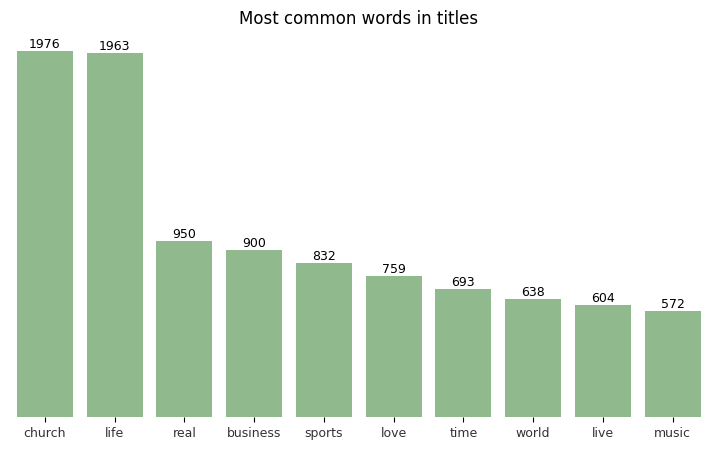

In [30]:
fig = plt.pyplot.figure(figsize=(9, 5))

ax = bar_plot_f(words_title_counts.head(10), "Most common words in titles", "#8BC087")
sns.despine(left=True, bottom=True)

There seems to be a lot of podcasts with chruch in it's title. It is more likely that these podcasts will have some religious undertones and/or they come from some church. Close second most common word is life – it is hard to tell what these about just from this word. It might be motivational podcosts about changing your life or something similar. The 3rd most popular word is real, which could be about real life stories or events. There are less than half of podcasts with this word compared to life in second place (950 vs 1963). Overall, looking at the most common words from podscast's titles we can guess what people like to speak about.

## Categories table

In [31]:
# Downloading table as CSV file for Dashboard:
file_exists = exists(r"data/categories.csv")
if not file_exists:
    categories.to_csv("data/categories.csv", sep=",", index=False, encoding="utf-8")

In [32]:
categories.shape

(212372, 2)

There are 212,372 rows in the categories table, which is more than podcasts. Therefore, it seems that some podcasts have several categories.

In [33]:
categories.dtypes

podcast_id    object
category      object
dtype: object

In [34]:
query = """
SELECT c.podcast_id, p.title, COUNT() category_count
FROM categories c
JOIN podcasts p ON c.podcast_id = p.podcast_id
GROUP BY c.podcast_id, p.title
ORDER BY COUNT() DESC, p.title
"""
pod_cat_counts = db.sql(query).df()
pod_cat_counts.head()

,podcast_id,title,category_count
0,fa8c359031380cd4f3b38358c8a75f92,Beyond Retirement,8
1,c4be70db3c16d3607bd7ae4999cb6e86,FrazerRice.Com,8
2,be905117ff9b3a13b1a065801241903b,Pursue Excellence,8
3,a7ae747331094b205de1e093011f7e1e,Be a Better Lawyer hosted by Dina Cataldo,7
4,b834bcf94406863e8484f4ee1f4d7bdf,Betches Brides,7


In [35]:
pod_cat_counts.category_count.describe()

count    110024.000000
mean          1.930233
std           0.974477
min           1.000000
25%           1.000000
50%           2.000000
75%           2.000000
max           8.000000
Name: category_count, dtype: float64

On average one podcast will have two categories. Median is two categories as well. At most the podcast will have 8 categories and there are 3 podcasts like that: Beyond Retirement, FrazerRice.Com and Pursue Execellence.

In [36]:
categories.category.unique()

array(['arts', 'arts-performing-arts', 'music', 'arts-design',
       'education', 'society-culture', 'arts-visual-arts', 'leisure',
       'leisure-hobbies', 'arts-books', 'technology',
       'society-culture-personal-journals',
       'society-culture-relationships', 'fiction',
       'fiction-science-fiction', 'arts-food',
       'education-language-learning', 'fiction-drama', 'true-crime',
       'health-fitness', 'health-fitness-nutrition', 'history', 'comedy',
       'arts-fashion-beauty', 'tv-film', 'society-culture-places-travel',
       'comedy-comedy-interviews', 'kids-family',
       'health-fitness-mental-health', 'religion-spirituality',
       'business', 'news', 'news-business-news', 'education-courses',
       'society-culture-philosophy', 'leisure-video-games',
       'tv-film-film-reviews', 'leisure-games', 'spirituality',
       'tv-film-film-history', 'business-careers',
       'business-entrepreneurship', 'science', 'science-earth-sciences',
       'comedy-improv'

In [37]:
len(categories.category.unique())

110

In total there are 110 unique categories.

In [38]:
cat_counts = categories.category.value_counts()
cat_counts.head()

category
society-culture          18710
education                12628
comedy                   12464
religion-spirituality    12190
business                 12058
Name: count, dtype: int64

In [39]:
cat_counts.tail()

category
science-physics        18
sports-swimming        18
science-chemistry      17
science-mathematics    16
sports-volleyball      14
Name: count, dtype: int64

In [40]:
cat_counts.describe()

count      110.000000
mean      1930.654545
std       3258.322196
min         14.000000
25%        288.250000
50%        727.000000
75%       1568.500000
max      18710.000000
Name: count, dtype: float64

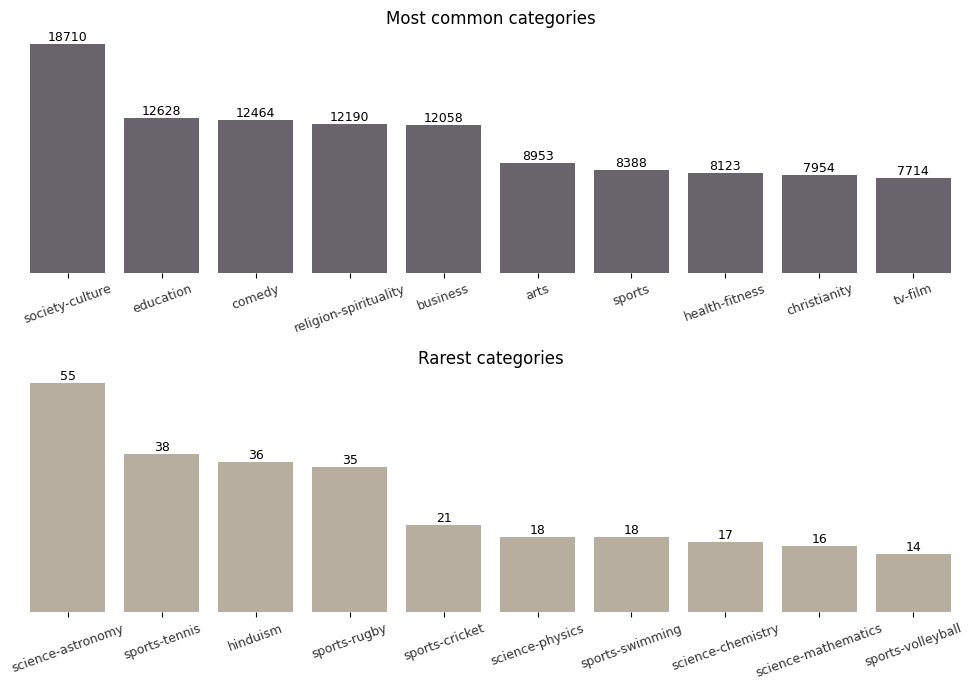

In [41]:
fig, axs = plt.pyplot.subplots(2, figsize=(10, 7))

ax0 = bar_plot_f(cat_counts.head(10), "Most common categories", "#69626D", ax=axs[0])
ax0.tick_params(axis="x", rotation=20)

ax1 = bar_plot_f(cat_counts.tail(10), "Rarest categories", "#BCAF9C", ax=axs[1])
ax1.tick_params(axis="x", rotation=20)

plt.pyplot.tight_layout()
sns.despine(left=True, bottom=True)

Most common podcast category is society-culture. Rarest is sports-volleyball, which seems to be specific sub-category of sports.

## Reviews table

In [42]:
reviews.shape

(2066874, 6)

There are 2,066,874 reviews in the dataset.

### Fixing date

In [43]:
reviews.dtypes

podcast_id    object
title         object
content       object
rating         int64
author_id     object
created_at    object
dtype: object

In [44]:
reviews.created_at.str[0].unique()

array(['2', '٢'], dtype=object)

There are two types of dates in the created_at column: one is presented in typical western number format, other is in arabic. To convert whole column to datetime we need to change arabic format to usual format.

In [45]:
mask = reviews.created_at.str.startswith("٢")
reviews.loc[mask]

,podcast_id,title,content,rating,author_id,created_at
686840,db93a05fe337aea2061b59c96e647100,What happened? Was it something I said?,I only listened to 4 podcasts but they were en...,5,3E66B9924F0D870,٢٠٢٠-١٢-٢٤T١١:٥٥:٠٨-07:00
686956,db93a05fe337aea2061b59c96e647100,NEWS RADIO FAN 4 life,"Joe is my source for Honest, Hard Hitting Com...",5,3BBAB440E06A8CB,٢٠٢٠-١٢-٢٤T٠٨:٢٦:٣٦-07:00


In [46]:
reviews.loc[mask, "created_at"] = reviews.loc[mask, "created_at"].apply(date_conv)

In [47]:
reviews.loc[mask]

,podcast_id,title,content,rating,author_id,created_at
686840,db93a05fe337aea2061b59c96e647100,What happened? Was it something I said?,I only listened to 4 podcasts but they were en...,5,3E66B9924F0D870,2020-12-24T11:55:08-07:00
686956,db93a05fe337aea2061b59c96e647100,NEWS RADIO FAN 4 life,"Joe is my source for Honest, Hard Hitting Com...",5,3BBAB440E06A8CB,2020-12-24T08:26:36-07:00


In [48]:
reviews["created_at"] = pd.to_datetime(reviews.created_at)
reviews.dtypes

podcast_id                       object
title                            object
content                          object
rating                            int64
author_id                        object
created_at    datetime64[ns, UTC-07:00]
dtype: object

In [49]:
# Downloading table as CSV file for Dashboard:
file_exists = exists(r"data/reviews.csv")
if not file_exists:
    query = """
    SELECT podcast_id, rating, created_at
    FROM reviews
    WHERE created_at BETWEEN '2018/01/01' AND '2023/01/01'
    """
    reviews_d = db.sql(query).df()
    reviews_d.to_csv("data/reviews.csv", sep=",", index=False, encoding="utf-8")

### Exploring reviews table

In [50]:
earliest = min(reviews["created_at"])
latest = max(reviews["created_at"])

print(f"Earliest review in the dataset is made on {earliest}")
print(f"Latest review in the dataset is made on   {latest}")

Earliest review in the dataset is made on 2005-12-09 21:41:01-07:00
Latest review in the dataset is made on   2023-02-16 08:38:37-07:00


In [51]:
query = """
SELECT MIN(created_at)
FROM reviews 
"""
earliest = db.sql(query).df().iloc[0, 0]

query = """
SELECT MAX(created_at)
FROM reviews 
"""
latest = db.sql(query).df().iloc[0, 0]

print(f"Earliest review in the dataset is made on {earliest}")
print(f"Latest review in the dataset is made on   {latest}")

Earliest review in the dataset is made on 2005-12-10 06:41:01+02:00
Latest review in the dataset is made on   2023-02-16 17:38:37+02:00


Note: using duckdb SQL time will be converted from UTC-7:00 to my timezone UTC+2:00, making 9 hour difference.

In [52]:
reviews.rating.describe()

count    2.066874e+06
mean     4.627080e+00
std      1.045890e+00
min      1.000000e+00
25%      5.000000e+00
50%      5.000000e+00
75%      5.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

Most of the reviews give 5 stars to the podcast.

In [53]:
query = """
SELECT rating, COUNT(rating) total
FROM reviews
GROUP BY rating
ORDER BY 1
"""
rating_dist = db.sql(query).df().set_index("rating").unstack().total
rating_dist

rating
1     116513
2      45852
3      52157
4      62856
5    1789496
dtype: int64

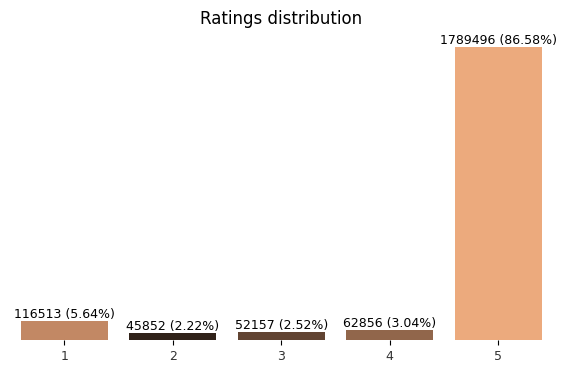

In [54]:
fig = plt.pyplot.figure(figsize=(7, 4))

custum_pal = rank_palette(rating_dist, "copper_r")
ax = bar_plot_f_perc(rating_dist, "Ratings distribution", rating_dist.sum(), custum_pal)

sns.despine(left=True, bottom=True)

Maximum rating is 5 stars and minimum is 1 star. Majority of ratings are 5 stars (86.58%). There are 5.64% of ratings for 1 star. This indicated that if listener liked the podcast they will give it 5 stars, and if they didn't they will give 1 star. Ratings of 2 to 4 stars aren't as likely to be given.

In [55]:
query = """
SELECT COUNT(author_id) author_count
FROM 
    (SELECT DISTINCT author_id 
    FROM reviews) sub
"""
db.sql(query)

┌──────────────┐
│ author_count │
│    int64     │
├──────────────┤
│      1475285 │
└──────────────┘

There are 1,475,285 different authors in the table

In [56]:
query = """
SELECT author_id, COUNT(author_id) reviews_written
FROM reviews
GROUP BY author_id
ORDER BY 2 DESC
"""
reviews_written = db.sql(query).df()
reviews_written.head()

,author_id,reviews_written
0,791F376ACA3C08D,615
1,D3307ADEFFA285C,615
2,96A3F0358E7808D,475
3,04C3B6DEFE22FB1,433
4,8858ED4249110B6,399


In [57]:
reviews_written.reviews_written.describe()

count    1.475285e+06
mean     1.401000e+00
std      2.132478e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      6.150000e+02
Name: reviews_written, dtype: float64

Majority of reviewers wrote just one review. There are two reviewers who wrote 615.

In [58]:
query = """
SELECT r.podcast_id, p.title, COUNT(r.podcast_id) reviews_rec, AVG(r.rating) rating
FROM reviews r
JOIN podcasts p ON p.podcast_id = r.podcast_id
GROUP BY r.podcast_id, p.title
ORDER BY 3 DESC
"""
reviews_received = db.sql(query).df()
reviews_received.head()

,podcast_id,title,reviews_rec,rating
0,bf5bf76d5b6ffbf9a31bba4480383b7f,Crime Junkie,33100,4.274894
1,bc5ddad3898e0973eb541577d1df8004,My Favorite Murder with Karen Kilgariff and Ge...,10673,3.606015
2,bad6c91efdbee814db985c7a65199604,Wow in the World,9694,4.776253
3,f5fce0325ac6a4bf5e191d6608b95797,The Ben Shapiro Show,8246,3.801965
4,f2377a9b0d9a2e0fb05c3dad55759328,Story Pirates,7382,4.735302


In [59]:
reviews_received.describe()

,reviews_rec,rating
count,110024.000000,110024.000000
mean,18.565504,4.810113
std,151.037736,0.568026
min,1.000000,1.000000
25%,1.000000,5.000000
50%,3.000000,5.000000
75%,8.000000,5.000000
max,33100.000000,5.000000


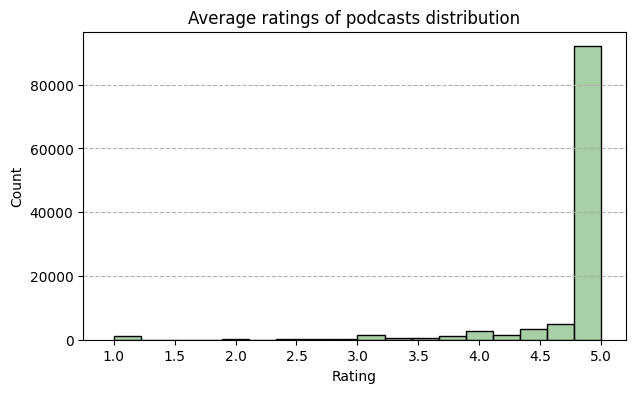

In [60]:
fig = plt.pyplot.figure(figsize=(7, 4))

ax = sns.histplot(data=reviews_received, x="rating", color="#8BC087")
ax.set(
    title="Average ratings of podcasts distribution",
    ylabel="Count",
    xlabel="Rating",
    xlim=0.75,
)
plt.pyplot.grid(axis="y", linestyle="--")

It looks like there are a lot of podcasts which do not have that many reviews. That seems to result in many podcasts with high rating. 

Let's check how results changes for podcats with more reviews: for example a hundred.

In [61]:
query = """
SELECT r.podcast_id, p.title, COUNT(r.podcast_id) reviews_rec, AVG(r.rating) rating
FROM reviews r
JOIN podcasts p ON p.podcast_id = r.podcast_id
GROUP BY r.podcast_id, p.title
HAVING COUNT(r.podcast_id) >= 100
ORDER BY 3 DESC
"""
reviews_received_100 = db.sql(query).df()
reviews_received_100.tail()

,podcast_id,title,reviews_rec,rating
3374,e2806f371e1a7d01b26274aac317267c,HAIYAA with Nigel Ng,100,4.83
3375,e4713942165d5ee8ad2cbb0f876d40de,Florida State Podcast of Entrepreneurship and ...,100,4.98
3376,f0c129c393043cd57a6ba74274074039,LashCast Podcast,100,4.91
3377,cdaaa0de5e85676d77a7e88a77f13639,Tequila Talk w/ Daisy Fuentes & Richard Marx,100,4.40
3378,e474ca19bf50ae2192bfb55ec82f1cce,NOBODY LIKES ONIONS,100,4.57


In [62]:
reviews_received_100.describe()

,reviews_rec,rating
count,3379.000000,3379.000000
mean,368.647233,4.635873
std,781.622080,0.450698
min,100.000000,1.701342
25%,137.000000,4.511757
50%,206.000000,4.810976
75%,405.000000,4.932912
max,33100.000000,5.000000


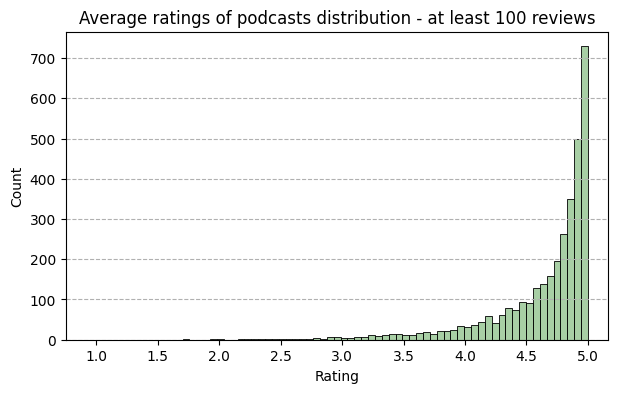

In [63]:
fig = plt.pyplot.figure(figsize=(7, 4))

ax = sns.histplot(data=reviews_received_100, x="rating", color="#8BC087")
ax.set(
    title="Average ratings of podcasts distribution - at least 100 reviews",
    ylabel="Count",
    xlabel="Rating",
    xlim=0.75,
)
plt.pyplot.grid(axis="y", linestyle="--")

Distribution is skewed to the left. The range is from 1.7 to 5 stars. Peak is around the maximum value of 5. There are some podcasts with 5 star rating although they had 100 reviews.

We can also check if amount of reviews left correlate with rating.

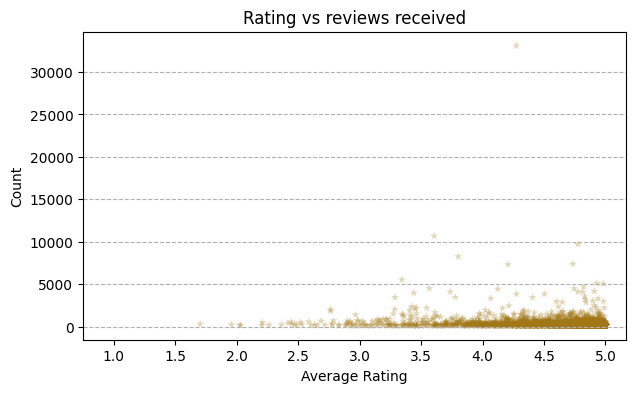

In [64]:
fig = plt.pyplot.figure(figsize=(7, 4))

ax = sns.scatterplot(
    data=reviews_received_100,
    x="rating",
    y="reviews_rec",
    alpha=0.3,
    marker="*",
    edgecolor="none",
    color="#A27816",
)
ax.set(
    title="Rating vs reviews received",
    ylabel="Count",
    xlabel="Average Rating",
    xlim=0.75,
)
plt.pyplot.grid(axis="y", linestyle="--")

There seems to be a lot of podcasts concentrated with not that many reviews, but high rating. We can check if there is any correlation between left review amount and podcasts ratings. 

In [65]:
stats.spearmanr(reviews_received_100.rating, reviews_received_100.reviews_rec)

SignificanceResult(statistic=-0.20028522711439506, pvalue=6.467414544374361e-32)

In [66]:
stats.pearsonr(reviews_received_100.rating, reviews_received_100.reviews_rec)

PearsonRResult(statistic=-0.1087040791382081, pvalue=2.368485768820606e-10)

For Pearson correlation measures linear correlation between data. Spearman's correlation does the same, but for monotonic associations between variables. Monotonicity is "less restrictive" than that of a linear relationship.

We can see that there is weak negative correlation for both Spearman and Pearson methods, with the first one being stronger (-0.2 vs -0.1). This might indicate that podcasts ratings do have a slight tendensy to get lower once a lot of reviews have been written. This effect might be because there are podcasts which are more popular or become trending, and, therefore, their audience is more varied – not everyone likes it the same way. Whereas less popular podcasts, which might not be trending, needs to be searched or of a particular subject which attracts certain audience who will like and enjoy the podcast either way.

In [67]:
query = """
SELECT datepart('year', created_at) AS year, 
       SUM(datepart('year', created_at)) total_reviews, 
       AVG(rating) mean_rating, STDDEV(rating) std
FROM reviews
GROUP BY 1
ORDER BY 1
"""
yearly_rating = db.sql(query).df()
yearly_rating

,year,total_reviews,mean_rating,std
0,2005,417040.0,4.798077,0.693375
1,2006,6768244.0,4.582395,1.002900
2,2007,11877426.0,4.532443,1.065798
3,2008,17063984.0,4.588021,1.016439
4,2009,22434503.0,4.566401,1.057479
5,2010,25926990.0,4.583301,1.057549
6,2011,35864174.0,4.622126,1.019974
7,2012,53124848.0,4.697508,0.917021
8,2013,51488514.0,4.721440,0.877407
9,2014,73583504.0,4.797460,0.757883


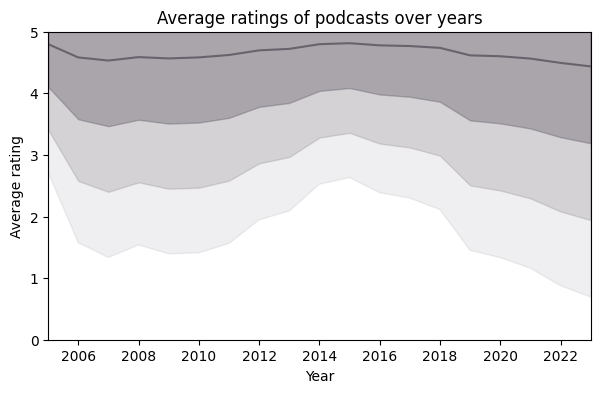

In [68]:
fig = plt.pyplot.figure(figsize=(7, 4))
ax = sns.lineplot(yearly_rating, x="year", y="mean_rating", color="#69626D")

lower = yearly_rating["mean_rating"] - yearly_rating["std"]
upper = yearly_rating["mean_rating"] + yearly_rating["std"]
ax.fill_between(yearly_rating.year, lower, upper, alpha=0.4, color="#69626D")

lower_95 = yearly_rating["mean_rating"] - 2 * yearly_rating["std"]
upper_95 = yearly_rating["mean_rating"] + 2 * yearly_rating["std"]
ax.fill_between(yearly_rating.year, lower_95, upper_95, alpha=0.2, color="#69626D")

lower_99 = yearly_rating["mean_rating"] - 3 * yearly_rating["std"]
upper_99 = yearly_rating["mean_rating"] + 3 * yearly_rating["std"]
ax.fill_between(yearly_rating.year, lower_99, upper_99, alpha=0.1, color="#69626D")

ax.set(
    title="Average ratings of podcasts over years",
    ylabel="Average rating",
    xlabel="Year",
    xlim=[2005, 2023],
    ylim=[0, 5],
);

Graph shows average podcasts rating over the years. Area painted around the graph is standard deviation $ σ $ (captures 68% of the data), lighter colors correspond to $ 2σ $ and $ 3σ $, which correspondingly captures 95% and 99.7% of the data. There is little fluctuation in average rating of podcasts over the years. Podcasts seems to be rated the highest around 2015. However, any difference between the years likely is due to random chance.

# Hypothesis testing

Since we have now explored the data, there are several questions, in which I am interested:

- Do people who do not like the podcast leave longer reviews?
- Are average ratings left during the winter lower compared to summer?
- Are more reviews left on podcasts about news-politics compared to science podcasts?

We can try to answer these questions using the data. Hypothesis testing will be applied to check if there is any statistical significance. $ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are few hypotheses Bonferroni Correction will be used: $ α $ is going to be divided by the number of hyphoteses made – 3 (which results to roughly 0.0167).

## Length of review

Do people, who listen to itunes podcasts, leave longer reviews if they did not like the podcast (left 1 star rating), compared to people who really enjoyed it (left 5 star rating).

$ H_0 $ will be that there is no difference between legth of left reviews. $ H_1 $ accordingly will be that there is a difference in length. 

In [69]:
query = """
SELECT rating, LEN(content) length
FROM reviews
"""
rew_len = db.sql(query).df()
rew_len.head()

,rating,length
0,4,136
1,5,82
2,5,53
3,5,120
4,5,201


In [70]:
rew_len.length.describe()

count    2.066874e+06
mean     2.392259e+02
std      2.406817e+02
min      2.000000e+01
25%      9.500000e+01
50%      1.770000e+02
75%      3.040000e+02
max      6.000000e+03
Name: length, dtype: float64

In [71]:
stats_plot = rew_len.groupby(["rating"]).length.agg(
    ["count", "mean", "min", "median", "max", "std", "sem"]
)
stats_plot

,count,mean,min,median,max,std,sem
rating,,,,,,,
1,116513,284.251929,20,190.0,6000,325.620776,0.953948
2,45852,353.531842,20,261.0,5999,341.183771,1.593343
3,52157,339.284142,20,249.0,6000,331.665958,1.452261
4,62856,295.067090,20,214.0,5985,298.142361,1.189187
5,1789496,228.487673,20,172.0,6000,222.955114,0.166668


In [72]:
rew_len.corr()

,rating,length
rating,1.000000,-0.097361
length,-0.097361,1.000000


There is weak negative correlation between length of the review and rating score.

In [73]:
mask = rew_len.rating == 1
rated_1 = rew_len.loc[mask, "length"]
rated_1_out = outlier_f(rated_1)
print(f"There are {rated_1_out.count()} outlier reviews rated 1 star.")
print(f"Every review length of {rated_1_out.min()} and longer is an outlier.")
rated_1_noout = rated_1.drop(rated_1_out.index)
assert len(rated_1_noout) + len(rated_1_out) == stats_plot.loc[1, "count"]

There are 7078 outlier reviews rated 1 star.
Every review length of 760 and longer is an outlier.


In [74]:
mask = rew_len.rating == 5
rated_5 = rew_len.loc[mask, "length"]
rated_5_out = outlier_f(rated_5)
print(f"There are {rated_5_out.count()} outlier reviews rated 5 stars.")
print(f"Every review length of {rated_5_out.min()} and longer is an outlier.")
rated_5_noout = rated_5.drop(rated_5_out.index)
assert len(rated_5_noout) + len(rated_5_out) == stats_plot.loc[5, "count"]

There are 91860 outlier reviews rated 5 stars.
Every review length of 595 and longer is an outlier.


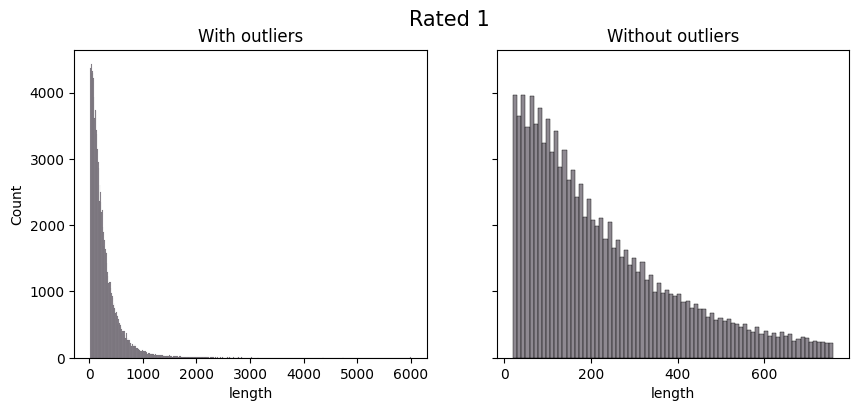

In [75]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))
fig.suptitle("Rated 1", fontsize=15)

ax0 = sns.histplot(rated_1, color="#69626D", ax=axs[0])
ax0.set(title="With outliers")
ax1 = sns.histplot(rated_1_noout, color="#69626D", ax=axs[1])
ax1.set(title="Without outliers");

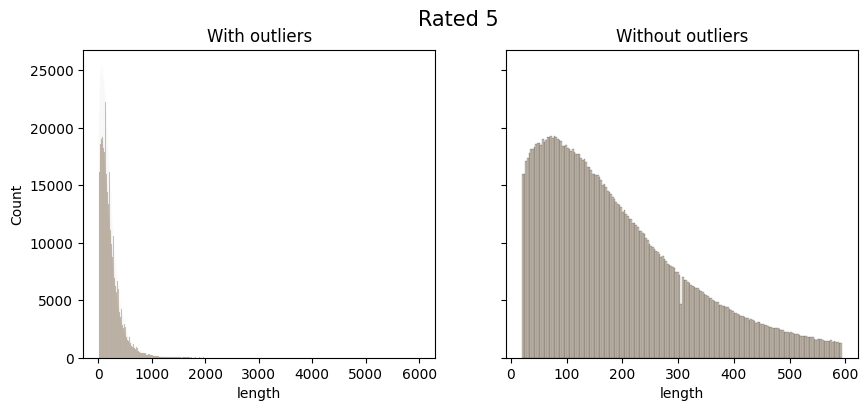

In [76]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))
fig.suptitle("Rated 5", fontsize=15)

ax0 = sns.histplot(rated_5, color="#BCAF9C", ax=axs[0])
ax0.set(title="With outliers")
ax1 = sns.histplot(rated_5_noout, color="#BCAF9C", ax=axs[1])
ax1.set(title="Without outliers");

Collected data for review lengh is right skewed and is not normally distributed. Majority of reviews are relatively short.

Since we have a lot of datapoints, we can apply Central limit theorem, and test hypothesis using t-test.

In [77]:
stats.ttest_ind(rated_1, rated_5)

TtestResult(statistic=79.99948627730555, pvalue=0.0, df=1906007.0)

In [78]:
conf_int_1 = stats.t.interval(
    0.95,
    df=len(rated_1) - 1,
    loc=stats_plot.loc[1, "mean"],
    scale=stats_plot.loc[1, "sem"],
)
conf_int_1

(282.38220490563214, 286.121653032967)

In [79]:
conf_int_5 = stats.t.interval(
    0.95,
    df=len(rated_5) - 1,
    loc=stats_plot.loc[5, "mean"],
    scale=stats_plot.loc[5, "sem"],
)
conf_int_5

(228.16100968141, 228.81433644956763)

Confidence intervals do not overlap. Also t-test returns very small p value. Therefore the difference is statisticaly significant. Because the distribution is not normal, Mann-Whitney U and Mood's median tests will also be performed.

The **Mann-Whitney U test** is a nonparametric test of the null hypothesis that the distribution underlying sample x is the same as the distribution underlying sample y. It is often used as a test of difference in location between distributions.

In [80]:
stats.mannwhitneyu(rated_1, rated_5)

MannwhitneyuResult(statistic=111829169411.5, pvalue=0.0)

It seems that p value is very small, therefore there is a difference between review lenghs is statistically significant according to this test. However, the low p value might also be due to having huge sample size. 

**Mood’s median test** - Test that two or more samples come from populations with the same median.

In [81]:
stats.median_test(rated_1, rated_5)

MedianTestResult(statistic=708.5536007915194, pvalue=4.1274654373357815e-156, median=172.0, table=array([[ 62642, 890085],
       [ 53871, 899411]], dtype=int64))

This test also returns that the difference between review lenghs is statistically significant.

Overall, we have evidence to reject null hyphotesis - that review lengths are same for 1 and 5 star ratings. Since the correlation between review rating and length is slightly negative, we can assume that reviews are slightly longer, when reviewer leaves review on podcast he did not like (1 star rating), compared to one he enjoyed (5 star rating).

## Summer vs Winter

Do people, who listen to itunes podcasts, on average leave different ratings during the winter, compared to summer.

$ H_0 $ will be that there is no difference between ratings. $ H_1 $ accordingly will be that there is a difference in ratings. 

In [82]:
query = """
SELECT datepart('month', created_at) AS month, rating
FROM reviews
"""
monthly = db.sql(query).df()
monthly.head()

,month,rating
0,4,4
1,8,5
2,8,5
3,8,5
4,8,5


In [83]:
stats_plot = monthly.groupby(["month"]).rating.agg(
    ["count", "mean", "min", "median", "max", "std", "sem"]
)
stats_plot

,count,mean,min,median,max,std,sem
month,,,,,,,
1,184909,4.619732,1,5.0,5,1.056550,0.002457
2,171832,4.655175,1,5.0,5,1.007605,0.002431
3,169419,4.633589,1,5.0,5,1.041681,0.002531
4,167764,4.644375,1,5.0,5,1.025494,0.002504
5,170228,4.641328,1,5.0,5,1.027999,0.002492
6,170854,4.612277,1,5.0,5,1.067459,0.002582
7,173411,4.625410,1,5.0,5,1.046961,0.002514
8,178350,4.625887,1,5.0,5,1.045358,0.002475
9,180178,4.623944,1,5.0,5,1.049787,0.002473


In [84]:
mask = monthly.month.isin([1, 2, 12])
winter = monthly[mask]
winter.rating.describe()

count    510369.000000
mean          4.627773
std           1.044197
min           1.000000
25%           5.000000
50%           5.000000
75%           5.000000
max           5.000000
Name: rating, dtype: float64

In [85]:
mask = monthly.month.isin([6, 7, 8])
summer = monthly[mask]
summer.rating.describe()

count    522615.00000
mean          4.62128
std           1.05318
min           1.00000
25%           5.00000
50%           5.00000
75%           5.00000
max           5.00000
Name: rating, dtype: float64

We can already see that there is very small difference between average ratings during summer and winter. Therefore even the diffrence will be statisticaly significant, it will not be very practical. Since there are a lot of datapoints, we can apply Central limit theorem, and test hypothesis using t-test.

In [86]:
stats.ttest_ind(summer.rating, winter.rating)

TtestResult(statistic=-3.1463491640469385, pvalue=0.0016532720257890251, df=1032982.0)

In [87]:
conf_int_w = stats.t.interval(
    0.95, df=len(winter) - 1, loc=winter.rating.mean(), scale=winter.rating.sem()
)
conf_int_w

(4.6249084719734626, 4.630638005183261)

In [88]:
conf_int_s = stats.t.interval(
    0.95, df=len(summer) - 1, loc=summer.rating.mean(), scale=summer.rating.sem()
)
conf_int_s

(4.618424168891099, 4.624134885097018)

We can see that results are statisticaly significant, since p value is 0.00165 and is less than 0.0167, however from confidence intervals are really close to each other, therefore we cannot fail null hypothesis confidentely.

Lets do the Mann-Whitney U test since the data might not be normaly distributed.

In [89]:
stats.mannwhitneyu(winter.rating, summer.rating)

MannwhitneyuResult(statistic=133647673420.0, pvalue=0.0015827734397026233)

Overall there seems to be a statistical difference between average ratings during summer and winter, however the difference is very small.

## News-politics podcasts compared to science podcasts

Do people, who listen to itunes podcasts on news-politics, on average leave more reviews compared to science podcats.

$ H_0 $ will be that there is no difference between average amount of reviews left. $ H_1 $ accordingly will be that there is a difference in amounts. 

In [90]:
query = """
SELECT r.podcast_id, p.title, COUNT(r.podcast_id) reviews_rec, AVG(r.rating) rating, c.category
FROM reviews r
JOIN podcasts p ON p.podcast_id = r.podcast_id
JOIN categories c ON c.podcast_id = r.podcast_id
GROUP BY r.podcast_id, p.title, c.category
ORDER BY 3 DESC
"""
reviews_amount = db.sql(query).df()
reviews_amount.head()

,podcast_id,title,reviews_rec,rating,category
0,bf5bf76d5b6ffbf9a31bba4480383b7f,Crime Junkie,33100,4.274894,true-crime
1,bc5ddad3898e0973eb541577d1df8004,My Favorite Murder with Karen Kilgariff and Ge...,10673,3.606015,comedy
2,bc5ddad3898e0973eb541577d1df8004,My Favorite Murder with Karen Kilgariff and Ge...,10673,3.606015,true-crime
3,bad6c91efdbee814db985c7a65199604,Wow in the World,9694,4.776253,kids-family-stories-for-kids
4,bad6c91efdbee814db985c7a65199604,Wow in the World,9694,4.776253,kids-family


In [91]:
mask = reviews_amount.category == "science"
science = reviews_amount[mask]
science.head()

,podcast_id,title,reviews_rec,rating,category
29,e6dc31392a05c976072c9aa83b27f567,Ologies with Alie Ward,4163,4.909200,science
279,a5416c179e94a74e61827c88e405b083,Invisibilia,1256,3.790605,science
303,c6e025d501ac8cc015870e2ddefd59f5,Science Vs,1197,3.542189,science
334,c648bb3380b09f9f08938c3b83d800a3,The Confessionals,1113,4.414196,science
357,ea4b525704af18de84441d0f37244cff,Real Ghost Stories Online,1056,4.039773,science


In [92]:
mask = reviews_amount.category == "news-politics"
politics = reviews_amount[mask]
politics.head()

,podcast_id,title,reviews_rec,rating,category
52,bede69aae211565459aceb5f7e8155d3,Pod Save America,3453,3.287286,news-politics
101,e8be02e7d7281ba3edb77da6a9fe95cd,FiveThirtyEight Politics,2068,3.451161,news-politics
220,a343c93505bffeaf20564bd2977b4743,Pantsuit Politics,1372,4.475948,news-politics
243,c946737844e536482a40d61b803d965a,Pod Save the World,1306,4.557427,news-politics
299,d5c8c35a332595a16c5f698b710695f4,Morning Joe,1212,3.362211,news-politics


To check if there are any podcasts which have both categories news-politics and science:

In [93]:
check = science.podcast_id.isin(politics.podcast_id)
check.any()

True

Since there are some podcasts which are in both categories, they will be removed from both datasets.

In [94]:
to_drop = science.podcast_id[check]
mask = science.podcast_id.isin(to_drop)
science = science[~mask]

mask = politics.podcast_id.isin(to_drop)
politics = politics[~mask]

check = science.podcast_id.isin(politics.podcast_id)
check.any()

False

In [95]:
science.reviews_rec.describe()

count    1932.000000
mean       23.817288
std       128.875502
min         1.000000
25%         1.000000
50%         3.000000
75%        10.000000
max      4163.000000
Name: reviews_rec, dtype: float64

In [96]:
politics.reviews_rec.describe()

count    1151.000000
mean       41.456125
std       169.376390
min         1.000000
25%         1.000000
50%         3.000000
75%        14.000000
max      3453.000000
Name: reviews_rec, dtype: float64

In [97]:
temp = outlier_f(science.reviews_rec)
print(f"There are {temp.count()} outlier reviews rated 1 star.")
print(f"Every pocast having {temp.min()} and more is an outlier.")
science_noout = science.drop(temp.index)

There are 274 outlier reviews rated 1 star.
Every pocast having 24 and more is an outlier.


In [98]:
temp = outlier_f(politics.reviews_rec)
print(f"There are {temp.count()} outlier reviews rated 1 star.")
print(f"Every pocast having {temp.min()} and more is an outlier.")
politics_noout = politics.drop(temp.index)

There are 167 outlier reviews rated 1 star.
Every pocast having 34 and more is an outlier.


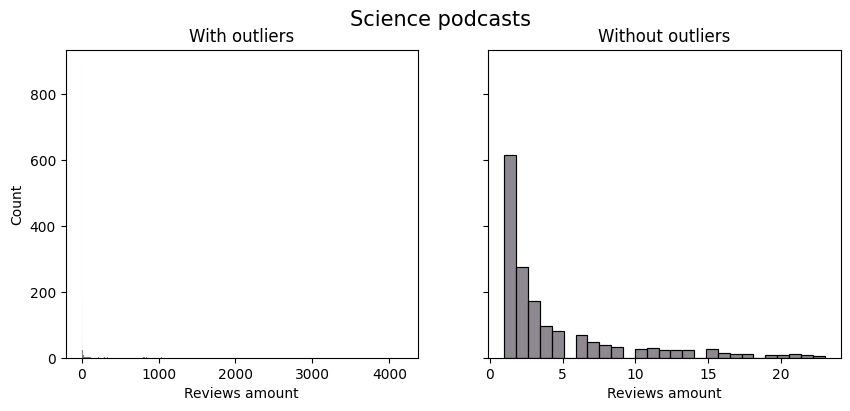

In [99]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))
fig.suptitle("Science podcasts", fontsize=15)

ax0 = sns.histplot(science.reviews_rec, color="#69626D", ax=axs[0])
ax0.set(title="With outliers", xlabel="Reviews amount")
ax1 = sns.histplot(science_noout.reviews_rec, color="#69626D", ax=axs[1])
ax1.set(title="Without outliers", xlabel="Reviews amount");

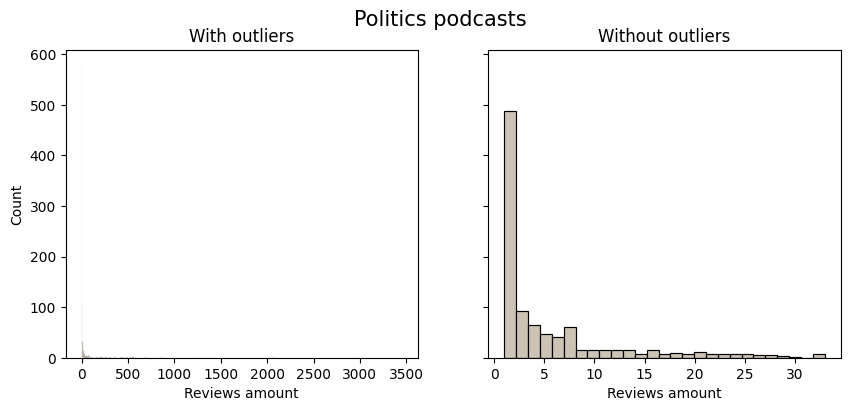

In [100]:
fig, axs = plt.pyplot.subplots(1, 2, sharey=True, figsize=(10, 4))
fig.suptitle("Politics podcasts", fontsize=15)

ax0 = sns.histplot(politics.reviews_rec, color="#BCAF9C", ax=axs[0])
ax0.set(title="With outliers", xlabel="Reviews amount")
ax1 = sns.histplot(politics_noout.reviews_rec, color="#BCAF9C", ax=axs[1])
ax1.set(title="Without outliers", xlabel="Reviews amount");

The distribution is skewd to the right. There are many outliers with a lot ot reviews recieved. Most of podcats recieved few reviews.

Since there are a lot of datapoints, we can apply Central limit theorem, and test hypothesis using t-test.

### With outliers

In [101]:
stats.ttest_ind(science.reviews_rec, politics.reviews_rec)

TtestResult(statistic=-3.2598822556025584, pvalue=0.0011267089580270998, df=3081.0)

In [102]:
conf_int_s = stats.t.interval(
    0.95,
    df=len(science) - 1,
    loc=science.reviews_rec.mean(),
    scale=science.reviews_rec.sem(),
)
conf_int_s

(18.067031479914423, 29.567544089443754)

In [103]:
conf_int_p = stats.t.interval(
    0.95,
    df=len(politics) - 1,
    loc=politics.reviews_rec.mean(),
    scale=politics.reviews_rec.sem(),
)
conf_int_p

(31.660760102857612, 51.25149011434482)

Difference there is statistical difference according to the t-test between podcasts, and we can reject null hypothesis in favor alternative. However, because the distribution of dataset is not normal, Mann Witney U test and Mood's median test will also be applied. 

In [104]:
stats.mannwhitneyu(science.reviews_rec, politics.reviews_rec)

MannwhitneyuResult(statistic=1040144.0, pvalue=0.0022911952716343094)

In [105]:
stats.median_test(science.reviews_rec, politics.reviews_rec)

MedianTestResult(statistic=5.755032862639081, pvalue=0.01644148809331429, median=3.0, table=array([[ 871,  571],
       [1061,  580]], dtype=int64))

There is statistical difference for Mann Whitney U test, and Mood's median, however, p value for median test is close to chosen significance level (0.0167).

### Without outliers

Going to do same tests on datasets without outliers, to see if there is a difference.

In [106]:
stats.ttest_ind(science_noout.reviews_rec, politics_noout.reviews_rec)

TtestResult(statistic=-5.348243017483458, pvalue=9.642459708591381e-08, df=2640.0)

In [107]:
conf_int_s_noout = stats.t.interval(
    0.95,
    df=len(science_noout) - 1,
    loc=science_noout.reviews_rec.mean(),
    scale=science_noout.reviews_rec.sem(),
)
conf_int_s_noout

(4.104917770691901, 4.564563532082526)

In [108]:
conf_int_p_noout = stats.t.interval(
    0.95,
    df=len(politics_noout) - 1,
    loc=politics_noout.reviews_rec.mean(),
    scale=politics_noout.reviews_rec.sem(),
)
conf_int_p_noout

(5.11661977786236, 5.96468103514577)

In [109]:
stats.mannwhitneyu(science_noout.reviews_rec, politics_noout.reviews_rec)

MannwhitneyuResult(statistic=758980.5, pvalue=0.0021143243217467728)

In [110]:
stats.median_test(science_noout.reviews_rec, politics_noout.reviews_rec)

MedianTestResult(statistic=4.172415743457957, pvalue=0.04108717723431286, median=2.0, table=array([[768, 497],
       [890, 487]], dtype=int64))

Once again, according to t-test and Mann Whitney U differences between populations are statisticaly significant. However, we can see that p value for Mood's median test now is higher than significance level, therefore we do not have enough evidence to fail null hyphothesis.

# Summary

* There seems to be a lot of podcasts with chruch in it's title. Close second most common word is life. The 3rd most popular word is real.
* On average one podcast will have two categories. At most the podcast will have 8 categories and there are 3 podcasts like that: Beyond Retirement, FrazerRice.Com and Pursue Execellence.
* Most common podcast category is society-culture. Rarest is sports-volleyball, which seems to be specific sub-category of sports.
* There are 2,066,874 reviews in the dataset.
* Majority of ratings are 5 stars (86.58%). There are 5.64% of ratings for 1 star. Ratings of 2 to 4 stars aren't as likely to be given.
* Majority of reviewers wrote just one review. There are two reviewers who wrote 615.
* There is weak negative correlation between left review amount and podcasts ratings.

Three hypotheses were tested to answer these questions I am interested in:

    Do people who do not like the podcast leave longer reviews?
    Are average ratings left during the winter lower compared to summer?
    Are more reviews left on podcasts about news-politics compared to science podcasts?

Confidence intervals were built, and t-test and Mann-Whitney U test were used for all hypothesies. For the 1st and 3rd were also tested with Mood's median test.

Results:
* There is statisticaly significant result that people, who listened itunes podcasts, leave longer reviews for the podcasts they do not like. This is indicated by weak negative correlation between rating and review length.
* There is statistical difference between ratings left on winter compared to summer (listeners tended to leave higher ratings during winter, compared to summer). However, the difference is small (confidence interval for winter is: 4.62491, 4.63064; for summer: (4.61842, 4.62413), and practicaly there is no difference.
* There is statistical difference between amount of reviews left on news-politics compared to science podcasts. However, they did fail one test, that is Mood's Median test, when the outliers are removed. Therefore, we cannot confidentaly say that we reject null hyphotesis.



# Suggestions for improvement

* Include permutation tests.
* More comparisons between categories and more investigations into categories.
* Investigate content of the reviews.
* Find a way to separate troll reviews (if it is clearly troll review).
* Create fancier dashboard.
* Separate more popular, higher reviewed podcasts from not so popular podcasts with few reviews.
* Do more timeline investigations, like weekday comparisons etc.